# Global Power Plant Database Analysis
**Author:** Husnain Zahoor  
**Date:** Nov 12, 2026  
**Dataset:** Global Power Plant Database v1.2.0 (released 2019-06-12), World Resources Institute and data contributors.

**Version check:** I also checked the newer WRI v1.3.0 (June 2021). Saudi Arabia has 90 plants there but no reported generation for 2013 to 2019, so it would not remove the Saudi generation gap.

**Decision:** I kept v1.2.0 because it meets all Must-Have requirements and switching would not fix the limitation. The newer version is noted as a limitation in the write-up.

**Source URL:** https://datasets.wri.org/dataset/globalpowerplantdatabase

**Downloaded from:** Kaggle copy of the WRI release, https://www.kaggle.com/datasets/mathurinache/global-power-plant-database
**Licence:** CC BY 4.0. Copyright 2018-2019 World Resources Institute and Data Contributors

**Credit:** Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, World Resources Institute. 2019. Global Power Plant Database.

---

### Context & Pipeline Position
This is notebook 3 of 5 (clustering). It works on **Sub-question 2**: Using capacity_mw, generation_gwh_2017, and commissioning_year, how many distinct plant clusters
emerge via K-means, and what is the average capacity/output per cluster?

**Inputs:** model_ready_plants.pkl (notebook 1): 8,778 plants, 28 columns.

**Outputs:** clustering_prepared_scaled.csv, plants_with_clusters.csv, and the findings text for Capstone_Findings.docx.

**Scope:** only plants that report 2017 generation. 95% are US (8,345), 431 are India, and 2 are other countries. These clusters describe mainly US plants, not the world and not Saudi Arabia.

# Environment Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
DATA_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Dataset/'
OUTPUT_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Output/'

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# FORCE PANDAS TO SHOW ALL COLUMNS HORIZONTALLY (NO WRAPPING)
pd.set_option('display.max_columns', None)  # Show every column
pd.set_option('display.width', 1000)        # Give the text engine plenty of horizontal width

# Loading the data set

In [5]:
df_final = pd.read_pickle(OUTPUT_PATH + 'model_ready_plants.pkl')
print(f'Loaded Successfully: {df_final.shape[0]} rows, {df_final.shape[1]} columns')

Loaded Successfully: 8778 rows, 28 columns


In [6]:
df_final.head(5)

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,other_fuel3,commissioning_year,owner,source,url,geolocation_source,wepp_id,year_of_capacity_data,generation_gwh_2013,generation_gwh_2014,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017,estimated_generation_gwh,commissioning_year_raw,flag_over_max,flag_negative_gen_2017,capacity_factor
12091,IND,India,AGARTALA GT,IND0000001,135.0,23.8712,91.3602,Gas,NaN,NaN,NaN,2004,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1024373,2018,631.777928,617.789264,843.7470,886.004428,663.774500,NaN,2004.0,False,False,0.561284
12092,IND,India,AKALTARA TPP,IND0000002,1800.0,21.9603,82.4091,Coal,Oil,NaN,NaN,2015,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1069957,2018,1668.290000,3035.550000,5916.3700,6243.000000,5385.579736,NaN,2015.0,False,False,0.341551
12093,IND,India,AKRIMOTA LIG,IND0000003,250.0,23.7689,68.6447,Coal,Oil,NaN,NaN,2005,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1017933,2018,821.798000,1153.421000,1208.8520,1175.765000,1147.913000,NaN,2005.0,False,False,0.524161
12094,IND,India,ALIYAR,IND0000004,60.0,10.4547,77.0078,Hydro,NaN,NaN,NaN,1970,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1030923,2018,147.568450,157.558250,152.1952,61.421350,89.629600,NaN,1970.0,False,False,0.170528
12095,IND,India,ALLAIN DUHANGAN,IND0000005,192.0,32.2258,77.2070,Hydro,NaN,NaN,NaN,2010,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1026499,2018,696.738800,674.391100,721.3352,675.724400,679.594950,NaN,2010.0,False,False,0.404059


## Exercise 1
Prepare your data for clustering. From your cleaned capstone dataset, select the numeric variables you believe say something about your research questions. Drop any categorical columns, k-means only works with numeric ones. Standardize the variables you keep. Submit your prepared, standardized data plus a short note: which variables you kept, which you dropped, and why.

0 0
Plants with exactly 0 generation: 317


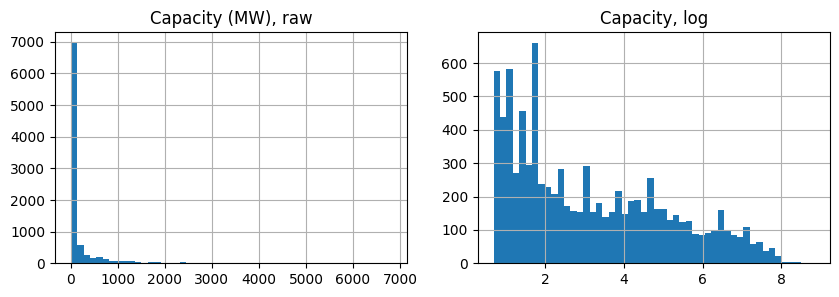

In [7]:
from sklearn.preprocessing import StandardScaler

# Safety check: log needs no negative values
print((df_final['capacity_mw'] <= 0).sum(), (df_final['generation_gwh_2017'] < 0).sum())
print("Plants with exactly 0 generation:", (df_final['generation_gwh_2017'] == 0).sum())

# Log transform the two skewed columns (new columns, originals kept)
df_final['log_capacity'] = np.log1p(df_final['capacity_mw'])
df_final['log_generation_2017'] = np.log1p(df_final['generation_gwh_2017'])

# Quick before/after picture (useful for write-up)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df_final['capacity_mw'].hist(bins=50, ax=ax[0]); ax[0].set_title('Capacity (MW), raw')
df_final['log_capacity'].hist(bins=50, ax=ax[1]); ax[1].set_title('Capacity, log')
plt.show()

# Choose variables and standardize
cluster_vars = df_final[['log_capacity', 'log_generation_2017', 'commissioning_year']]
scaler = StandardScaler()
cluster_vars_scaled = scaler.fit_transform(cluster_vars)

# Save the prepared data.
scaled_df = pd.DataFrame(cluster_vars_scaled, columns=cluster_vars.columns, index=cluster_vars.index)
scaled_df.to_csv(OUTPUT_PATH + 'clustering_prepared_scaled.csv')

**Variables kept:** log_capacity and log_generation_2017 (the log of capacity_mw and generation_gwh_2017), plus commissioning_year. These are the three named in Sub-question 2. The before/after chart shows the log turns one big spike of small plants into a spread-out shape.

**Dropped, categorical (k-means needs numbers):** country, primary_fuel, owner, source and the other text columns. I use primary_fuel later to explain the clusters, not to build them.

**Dropped, numeric:** the other generation years (correlate 0.91 to 0.97 with 2017, so they add nothing new), estimated_generation_gwh (a WRI model estimate, not measured), capacity_factor (it is calculated from capacity and generation, so it would count the same information twice), latitude and longitude (used for maps), and year_of_capacity_data (not a plant characteristic).

**Log transform:** capacity and generation are heavily skewed (in the full database, median 18.9 MW vs mean 186 MW). Without a log, a few giant plants would dominate the distance calculation. I applied log1p to both.

**Standardization:** after the log, the three variables are on very different scales (years around 2,000 vs logs around 2 to 10), so I standardized them with StandardScaler so no variable counts more just because its numbers are bigger.

**Zero output:** 317 plants (3.6%) report exactly 0 GWh in 2017. I kept them because log1p handles zeros, and removing them would hide real idle plants. They may also be missing reports.

## Exercise 2
Find your optimal number of clusters. Run the elbow technique across a range of possible cluster counts and plot the results. Choose a number of clusters based on where the curve bends, not by default. Submit your elbow plot plus a markdown cell explaining the number you chose and why.

In [8]:
from sklearn.cluster import KMeans   # Loaded the KMeans Tools

num_clusters = range(1, 10)  # No of clusters we want to test
kmeans_models = [KMeans(n_clusters=i, random_state=42, n_init=10) for i in num_clusters]  # Builds 9 k-means models, one for each number.
scores = [kmeans_models[i].fit(cluster_vars_scaled).score(cluster_vars_scaled)for i in range(len(kmeans_models))]   # Trains each model on standardized data and records its score.

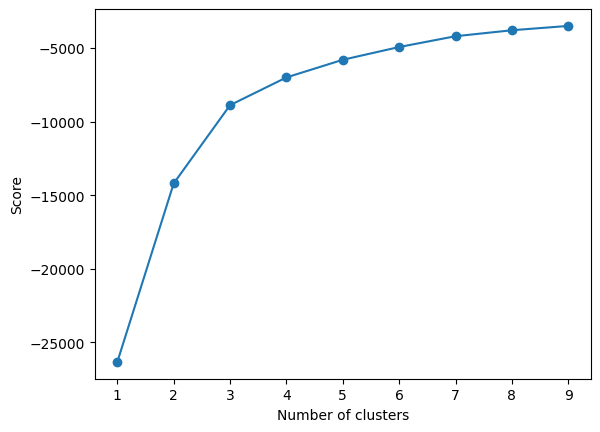

In [9]:
import matplotlib.pyplot as plt

plt.plot(list(num_clusters), scores, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Score")
plt.show()

In [10]:
elbow = pd.DataFrame({'k': list(num_clusters), 'score': scores})
elbow['improvement'] = elbow['score'].diff()
print(elbow.round(1))

   k    score  improvement
0  1 -26334.0          NaN
1  2 -14200.9      12133.1
2  3  -8879.3       5321.6
3  4  -6994.6       1884.7
4  5  -5794.5       1200.0
5  6  -4927.6        866.9
6  7  -4193.0        734.6
7  8  -3787.5        405.6
8  9  -3492.8        294.6


I tested k = 1 to 9. The score improves by 12,133 from k=1 to 2, 5,322 from 2 to 3, 1,885 from 3 to 4, and 1,200 from 4 to 5. The gain falls by about two-thirds after k = 3 (from 5,322 to 1,885), so I chose k = 3. k = 4 was also reasonable but adds little.

## Exercise 3
Run k-means and visualize your clusters. Fit k-means with your chosen number of clusters, add the resulting labels to your dataframe, and check how many observations fall into each cluster. Build at least one 2D scatterplot and one 3D scatterplot, each colored by cluster, using different variable combinations. Submit your Colab notebook with the fitted model and both visualizations.

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)  # creates one k-means model with 3 clusters. This is the final model, not a test.
kmeans.fit(cluster_vars_scaled)   # The model finds 3 centre points and assigns every plant to the nearest one.

df_final["cluster"] = kmeans.labels_   # kmeans.labels_ is a list of 8,778 numbers (0, 1 or 2), one per plant, in the same row order as df_final. Saving it as df_final["cluster"] attaches each plant’s cluster to the table.
df_final["cluster"].value_counts()  # Counts how many plants are in each cluster.

,count
cluster,
1,4717
0,2911
2,1150


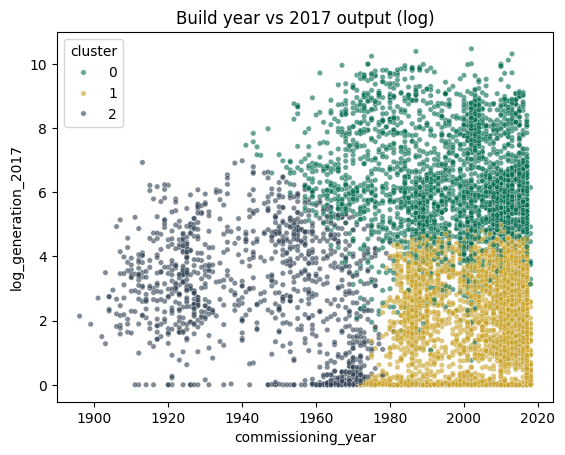

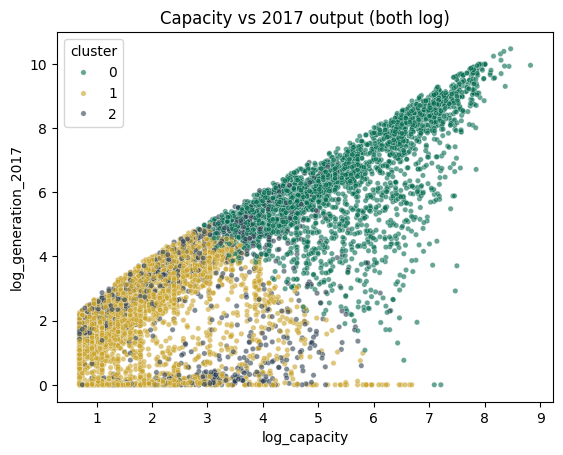

In [12]:
sns.scatterplot(data=df_final, x="commissioning_year", y="log_generation_2017", hue="cluster",
                palette=["#006A4E", "#C9A227", "#2C3E50"], s=15, alpha=0.6)
plt.title("Build year vs 2017 output (log)")
plt.show()

sns.scatterplot(data=df_final, x="log_capacity", y="log_generation_2017", hue="cluster",
                palette=["#006A4E", "#C9A227", "#2C3E50"], s=15, alpha=0.6)
plt.title("Capacity vs 2017 output (both log)")
plt.show()


In [13]:
import plotly.express as px

fig = px.scatter_3d(df_final.assign(cluster=df_final["cluster"].astype(str)),
                    x="log_capacity", y="commissioning_year", z="log_generation_2017",
                    color="cluster", opacity=0.6,
                    color_discrete_map={"0": "#006A4E", "1": "#C9A227", "2": "#2C3E50"})
fig.update_traces(marker_size=2)
fig.show()

**Cluster sizes:** cluster 1 has 4,717 plants (53.7%), cluster 0 has 2,911 (33.2%), cluster 2 has 1,150 (13.1%). None is tiny or huge.

**Plot 1 (build year vs output):** cluster 2 (navy) holds the older plants, mostly built before about 1975. Cluster 1 (gold) is newer plants with low output. Cluster 0 (green) is plants with high output, mostly built from the 1960s on.

**Plot 2 (capacity vs output):** cluster 0 (green) holds the larger plants, roughly 50 MW and above. Clusters 1 and 2 overlap among small plants bbecause they differ mainly by age.

**3D plot:** with all three variables together, the three groups sit in different areas. Their edges touch, which is normal for k-means.

## Exercise 4
Interpret your clusters. Calculate descriptive statistics per cluster and describe what distinguishes them. Give each cluster a short, descriptive name. State whether the clusters make sense, connect them to your research questions, and propose what these patterns could be useful for later, including what you might test formally with regression in Lesson 5. Record this in your running Capstone_Findings.docx. Submit your written interpretation.

Explains the clusters (fuel and country):

In [14]:
# Which fuels are in each cluster (% of each cluster)
fuel = (pd.crosstab(df_final['cluster'], df_final['primary_fuel'], normalize='index') * 100).round(0).T
fuel.columns = [f'Cluster {c}' for c in fuel.columns]
fuel = fuel[(fuel >= 1).any(axis=1)]
display(fuel.sort_values('Cluster 0', ascending=False)
            .style.background_gradient(cmap='YlGn', axis=None).format('{:.0f}%'))

# Which countries are in each cluster
country = pd.crosstab(df_final['cluster'], df_final['country']).T
country.columns = [f'Cluster {c}' for c in country.columns]
display(country)

,Cluster 0,Cluster 1,Cluster 2
primary_fuel,,,
Gas,34%,12%,15%
Wind,21%,9%,0%
Coal,16%,1%,2%
Hydro,12%,10%,67%
Solar,5%,45%,0%
Waste,5%,9%,1%
Biomass,2%,2%,1%
Nuclear,2%,0%,0%
Geothermal,1%,1%,0%


,Cluster 0,Cluster 1,Cluster 2
country,,,
IND,363,44,24
MAR,1,0,0
USA,2546,4673,1126
ZAF,1,0,0


Names plus the one results table:

In [15]:
names = {0: "Large Mixed-Fuel Plants", 1: "Small Newer Solar-Heavy Plants", 2: "Small Older Hydro-Heavy Plants"}
df_final["cluster_name"] = df_final["cluster"].astype(int).map(names)

results = (df_final.groupby('cluster_name')
    .agg(Plants=('capacity_mw', 'size'),
         Median_capacity_MW=('capacity_mw', 'median'),
         Median_output_GWh=('generation_gwh_2017', 'median'),
         Median_build_year=('commissioning_year', 'median'),
         Median_capacity_factor_pct=('capacity_factor', lambda s: s.median() * 100)))
tot = df_final.groupby('cluster_name')[['capacity_mw', 'generation_gwh_2017']].sum()
results['Share_of_capacity_pct'] = tot['capacity_mw'] / tot['capacity_mw'].sum() * 100
results['Share_of_output_pct'] = tot['generation_gwh_2017'] / tot['generation_gwh_2017'].sum() * 100
display(results.round(1).sort_values('Plants', ascending=False))

,Plants,Median_capacity_MW,Median_output_GWh,Median_build_year,Median_capacity_factor_pct,Share_of_capacity_pct,Share_of_output_pct
cluster_name,,,,,,,
Small Newer Solar-Heavy Plants,4717,4.4,5.5,2012.0,19.3,3.8,1.2
Large Mixed-Fuel Plants,2911,199.6,408.4,2001.0,35.2,93.6,97.3
Small Older Hydro-Heavy Plants,1150,15.0,18.9,1950.5,34.0,2.7,1.5


In [16]:
df_final.to_csv(OUTPUT_PATH + 'plants_with_clusters.csv', index=False)

**Results (typical plant = median).**

**Large Mixed-Fuel Plants (cluster 0):** 2,911 plants (33%). Typical plant: 200 MW, built 2001, 408 GWh in 2017, runs at 35% of its maximum possible output (capacity factor). Fuels: gas 34%, wind 21%, coal 16%, hydro 12%.

**Small Newer Solar-Heavy Plants (cluster 1):** 4,717 plants (54%). 4.4 MW, built 2012, 5.5 GWh, 19% capacity factor. 45% solar.

**Small Older Hydro-Heavy Plants (cluster 2):** 1,150 plants (13%). 15 MW, built 1950, 18.9 GWh, 34% capacity factor. 67% hydro.

**Main result:** the large plants are 33% of plants but hold 93.6% of capacity and produce 97.3% of 2017 output. The other two groups together produce 2.7%.

**What separates them:** size first (cluster 0 is far larger). Then how hard plants run: capacity factor is 19% for the small newer group vs 35% and 34% for the others. Then age, which separates the two small groups (2012 vs 1950). Fuel goes with age: the newer group is 45% solar and the older group is 67% hydro.

**Median vs mean:** I use medians because a few giant plants pull the means up (cluster 0: mean 1,716 GWh vs median 408 GWh).

**Do the clusters make sense?** Yes. Each has a clear profile and sits in a different area of the plots. Edges overlap, which is normal for k-means.

**Hypotheses:** H1 (size first, then how hard plants run) is supported. H2 (clusters separate fuels) is partly supported: clusters 1 and 2 are fuel-heavy, but cluster 0 is mixed. H3 (age does not define a cluster) is not supported: age helps separate the two small groups, though it may be linked to fuel.

**Answer to Sub-question 2:** three plant types emerge (k = 3), with the averages above.

**Use for Lesson 5:** test whether capacity is the strongest predictor of output, whether fuel adds information, and whether build year adds anything beyond fuel and size.

**Limits:** 8,345 of 8,778 plants are US and 431 are Indian. No Saudi plant is included. 317 plants with zero output are kept. Clustering describes patterns and does not prove causes.